<a href="https://colab.research.google.com/github/npmauad/dataeng/blob/main/notebooks/TP3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Trabajo Práctico N° 3**

*Declaración de uso de IA: Utilicé Claude Sonnet 5.5 Medium para ayuda en la escritura del código y resolución de dudas.*

**1.1.1. Importar los archivos correspondientes a eventos posteriores al 08-10-2026**

In [14]:
# Importar los paquetes necesarios

import requests
import io
import zipfile
import pandas as pd

# Traer la lista de archivos con get
url_to_get = "https://data.gdeltproject.org/gdeltv2/masterfilelist.txt"
masterfile = requests.get(url_to_get)
lines = masterfile.text.splitlines()

# Quedarnos solo con los archivos desde el 08-10-2026
datefrom = "20261008"

export_urls = []
for line in lines:
    parts = line.split(" ")
    file_url = parts[-1]  # formato: "tamaño hash URL"
    if file_url.endswith(".export.CSV.zip"):
        filedate = file_url.split("/")[-1][:8]  # primeros 8 dígitos del nombre
        if filedate >= datefrom:
            export_urls.append(file_url)

print(f"Archivos a descargar: {len(export_urls)}")

Archivos a descargar: 782


**1.1.2. Definir columnas. Descargar y leer cada archivo, y unificarlos en un solo DataFrame**

In [15]:

# Columnas del codebook GDELT 2.0 que necesitamos, con su posición
COLS_IDX = [0, 5, 15, 29, 30, 34, 53]
COLS_NAMES = ["GlobalEventID", "Actor1Code", "Actor2Code", "QuadClass", "GoldsteinScale", "AvgTone", "ActionGeo_CountryCode"]

# Función para leer cada archivo
def read_export_zip(file_url):
    r = requests.get(file_url)
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        nombre_csv = z.namelist()[0]
        with z.open(nombre_csv) as f:
            df = pd.read_csv(
                f,
                sep="\t",
                header=None,
                usecols=COLS_IDX,
                names=COLS_NAMES,
                dtype={"Actor1Code": "string", "Actor2Code": "string",
                       "QuadClass": "int16", "GoldsteinScale": "float", "AvgTone": "float", "ActionGeo_CountryCode": "string"}
            )
    return df

# Descargar todo y unificar en un solo DataFrame
dfs = []
for i, u in enumerate(export_urls):
    dfs.append(read_export_zip(u))
    if i % 50 == 0:
        print(f"  {i}/{len(export_urls)} descargados")
df_events = pd.concat(dfs, ignore_index=True)
print(df_events.shape)

  0/782 descargados
  50/782 descargados
  100/782 descargados
  150/782 descargados
  200/782 descargados
  250/782 descargados
  300/782 descargados
  350/782 descargados
  400/782 descargados
  450/782 descargados
  500/782 descargados
  550/782 descargados
  600/782 descargados
  650/782 descargados
  700/782 descargados
  750/782 descargados
(864002, 7)


**1.1.3. Construir las tablas normalizadas para el almacén de datos**

In [16]:
# DIM_ACTOR: valores únicos de actores (combinando Actor1 y Actor2)
actores_unicos = pd.concat([df_events["Actor1Code"], df_events["Actor2Code"]]).unique()
dim_actor = pd.DataFrame({"ActorCode": actores_unicos})
dim_actor["actor_key"] = range(1, len(dim_actor) + 1)

# DIM_UBICACION: valores únicos de país
paises_unicos = df_events["ActionGeo_CountryCode"].unique()
dim_ubicacion = pd.DataFrame({"CountryCode": paises_unicos})
dim_ubicacion["ubicacion_key"] = range(1, len(dim_ubicacion) + 1)

# HECHOS: el DataFrame original, pero reemplazando los códigos por sus keys (FK)
hechos = df_events.merge(dim_actor, left_on="Actor1Code", right_on="ActorCode") \
                   .rename(columns={"actor_key": "actor1_key"}) \
                   .drop(columns=["ActorCode", "Actor1Code"])

hechos = hechos.merge(dim_actor, left_on="Actor2Code", right_on="ActorCode") \
               .rename(columns={"actor_key": "actor2_key"}) \
               .drop(columns=["ActorCode", "Actor2Code"])

hechos = hechos.merge(dim_ubicacion, left_on="ActionGeo_CountryCode", right_on="CountryCode") \
               .drop(columns=["CountryCode", "ActionGeo_CountryCode"])

hechos = hechos[["GlobalEventID", "actor1_key", "actor2_key", "ubicacion_key",
                  "QuadClass", "GoldsteinScale", "AvgTone"]]

**1.1.4. Volcar a SQLite**

In [17]:
import sqlite3

conn = sqlite3.connect("gdelt_dw.db")

dim_actor.to_sql("DIM_ACTOR", conn, if_exists="replace", index=False)
dim_ubicacion.to_sql("DIM_UBICACION", conn, if_exists="replace", index=False)
hechos.to_sql("HECHOS", conn, if_exists="replace", index=False)

conn.commit()

**1.1.5. Reconstruir la matriz de análisis**

In [18]:
query = """
SELECT
    h.GlobalEventID,
    a1.ActorCode AS Actor1Code,
    a2.ActorCode AS Actor2Code,
    h.QuadClass,
    h.GoldsteinScale,
    h.AvgTone,
    u.CountryCode AS ActionGeo_CountryCode
FROM HECHOS h
JOIN DIM_ACTOR a1 ON h.actor1_key = a1.actor_key
JOIN DIM_ACTOR a2 ON h.actor2_key = a2.actor_key
JOIN DIM_UBICACION u ON h.ubicacion_key = u.ubicacion_key
"""

df_analisis = pd.read_sql(query, conn)
df_analisis.head()

,GlobalEventID,Actor1Code,Actor2Code,QuadClass,GoldsteinScale,AvgTone,ActionGeo_CountryCode
0,1326831366,BUS,GOV,1,2.8,3.321033,US
1,1326831367,BUS,USA,1,1.9,3.321033,US
2,1326831368,DEU,None,2,7.4,2.121212,GM
3,1326831369,GOV,BUS,1,1.9,3.321033,IR
4,1326831370,IGOEUREEC,BUS,1,3.0,-5.721393,BE


**1.2. Limpiar datos vacíos, reducir cardinalidad**

In [19]:
def reducir_cardinalidad(serie, umbral=0.05):
    frecuencias = serie.value_counts(normalize=True)
    categorias_frecuentes = frecuencias[frecuencias >= umbral].index
    return serie.where(serie.isin(categorias_frecuentes), "OTHER")

# Copia para no modificar df_analisis (así la celda se puede volver a correr)
df_reducido = df_analisis.copy()

for col in ["Actor1Code", "Actor2Code", "ActionGeo_CountryCode"]:
    df_reducido[col] = reducir_cardinalidad(df_reducido[col])

# Verificar: debería dar pocas categorías por columna (QuadClass queda en 4)
print(df_reducido[["Actor1Code", "Actor2Code", "QuadClass", "ActionGeo_CountryCode"]].nunique())

Actor1Code               3
Actor2Code               3
QuadClass                4
ActionGeo_CountryCode    4
dtype: int64


**1.3/4. Convertir las variables categóricas en dummies y construir la matriz de datos**

In [20]:
df_matriz = pd.get_dummies(
    df_reducido.set_index("GlobalEventID"),
    columns=["Actor1Code", "Actor2Code", "QuadClass", "ActionGeo_CountryCode"],
    dtype="int8"
)


**2.1. Cálculo del vector de medias y análisis de las distancias**

Topográficamente, se puede observar que EEUU representa el perfil más atípico (distancia 1,01 con respecto a la media global, y más de 1,4 de cualquier otro país incluido). El resto de los perfiles son más parecidos entre sí, y "Others" resulta el perfil más similar al global, lo cual resulta lógico teniendo en cuenta que representa países de todo el mundo con valores heterogeneos.
AvgTone, GoldsteinScale y QuadClass no se observan muy diferentes entre los distintos países, siendo la mayor parte de la diferencia explicable por los diferentes actores involucrados en cada caso.

In [21]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform

# 1. Matriz sin las dummies de país + vector con el país de cada fila
cols_pais = [c for c in df_matriz.columns if c.startswith("ActionGeo_CountryCode_")]
X = df_matriz.drop(columns=cols_pais)
pais = df_reducido["ActionGeo_CountryCode"].to_numpy()

# 2. Vector de medias global en unidades originales (para interpretar)
media_global_orig = X.mean()

# 3. Estandarizar
X_z = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)

# 4. Vectores de medias (estandarizados): global + uno por país
medias_pais = X_z.groupby(pais).mean()
medias = pd.concat([X_z.mean().to_frame("GLOBAL").T, medias_pais])

# 5. Distancias euclídeas entre todos los vectores
dist = pd.DataFrame(
    squareform(pdist(medias.values, metric="euclidean")),
    index=medias.index, columns=medias.index
)

print(media_global_orig.round(3)) # Vector de medias global
print(medias.round(3)) # Vector de medias de cada país
print(dist.round(3)) # Distancias entre cada país y con el global

GoldsteinScale      0.419
AvgTone            -2.106
Actor1Code_GOV      0.077
Actor1Code_OTHER    0.794
Actor1Code_USA      0.130
Actor2Code_GOV      0.052
Actor2Code_OTHER    0.858
Actor2Code_USA      0.090
QuadClass_1         0.611
QuadClass_2         0.112
QuadClass_3         0.140
QuadClass_4         0.138
dtype: float64
        GoldsteinScale  AvgTone  Actor1Code_GOV  Actor1Code_OTHER  \
GLOBAL          -0.000    0.000           0.000            -0.000   
IN              -0.111   -0.080           0.140             0.196   
OTHER            0.008    0.007           0.017             0.211   
UK               0.038    0.161          -0.023             0.268   
US               0.003   -0.024          -0.059            -0.486   

        Actor1Code_USA  Actor2Code_GOV  Actor2Code_OTHER  Actor2Code_USA  \
GLOBAL          -0.000          -0.000             0.000           0.000   
IN              -0.348           0.109             0.160          -0.280   
OTHER           -0.267        

**2.2. Matriz de correlaciones**

Se observa en diagonal la correlación de 1.0 entre las variables idénticas.
Se pueden ver también correlaciones esperables por la naturaleza de los datos. Por ejemplo, la correlación negativa entre los distintos dummies de una misma variable, como los 4 de QuadClass.
Entre las correlaciones no mecánicas, si bien esperables, se puede observar la correlación positiva entre GoldsteinScale y los valores de QuadClass correspondientes a cooperación, y negativa entre esta misma escala y los valores correspondientes a conflictos; así como la correlación positiva entre GoldsteinScale y AvgTone.

Las dummies de actores casi no se correlacionan con GoldsteinScale, AvgTone ni QuadClass: quién participa no predice el tipo de evento ni el tono de su cobertura.

Por país, las relaciones entre GoldsteinScale, AvgTone y QuadClass se mantienen estables. Las diferencias se dan en los actores: en EE. UU. se acentúa el contraste agente/receptor, y en India Actor1Code_GOV vs. Actor1Code_OTHER pasa de -0.57 a -0.9, porque casi no hay actores estadounidenses y la identificación se reduce a "gobierno" u "otro".

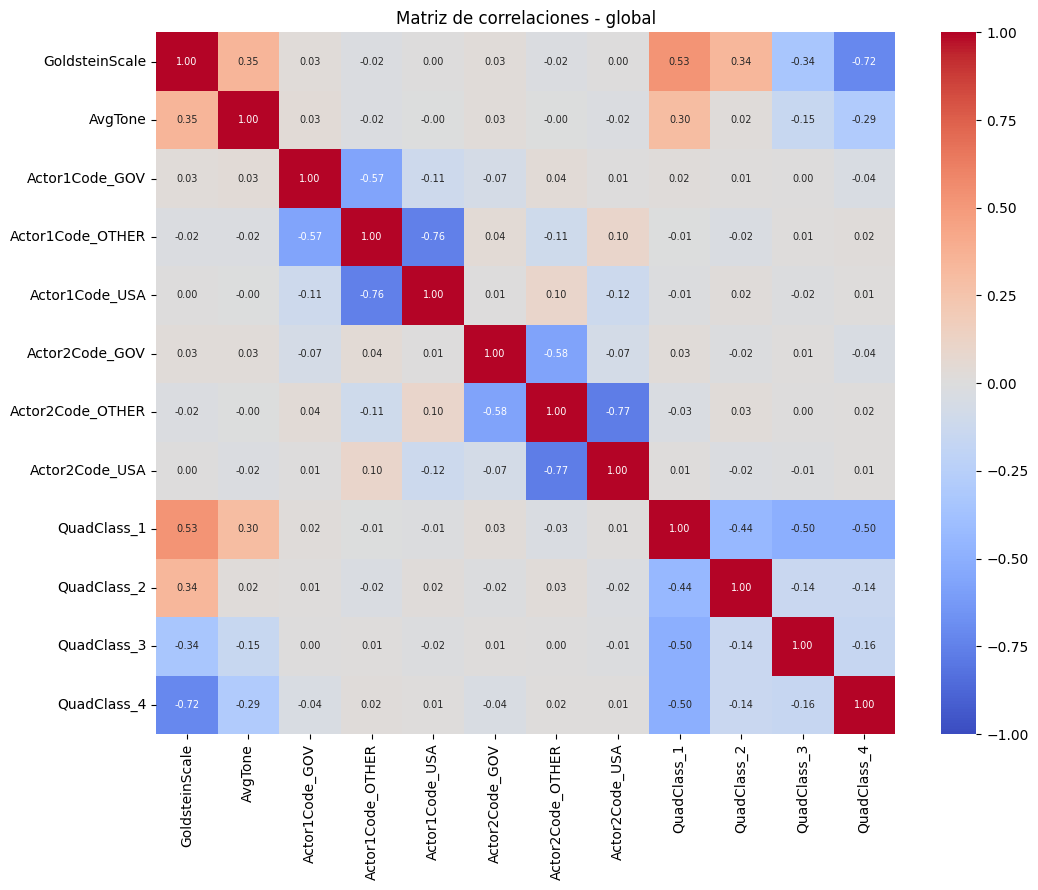

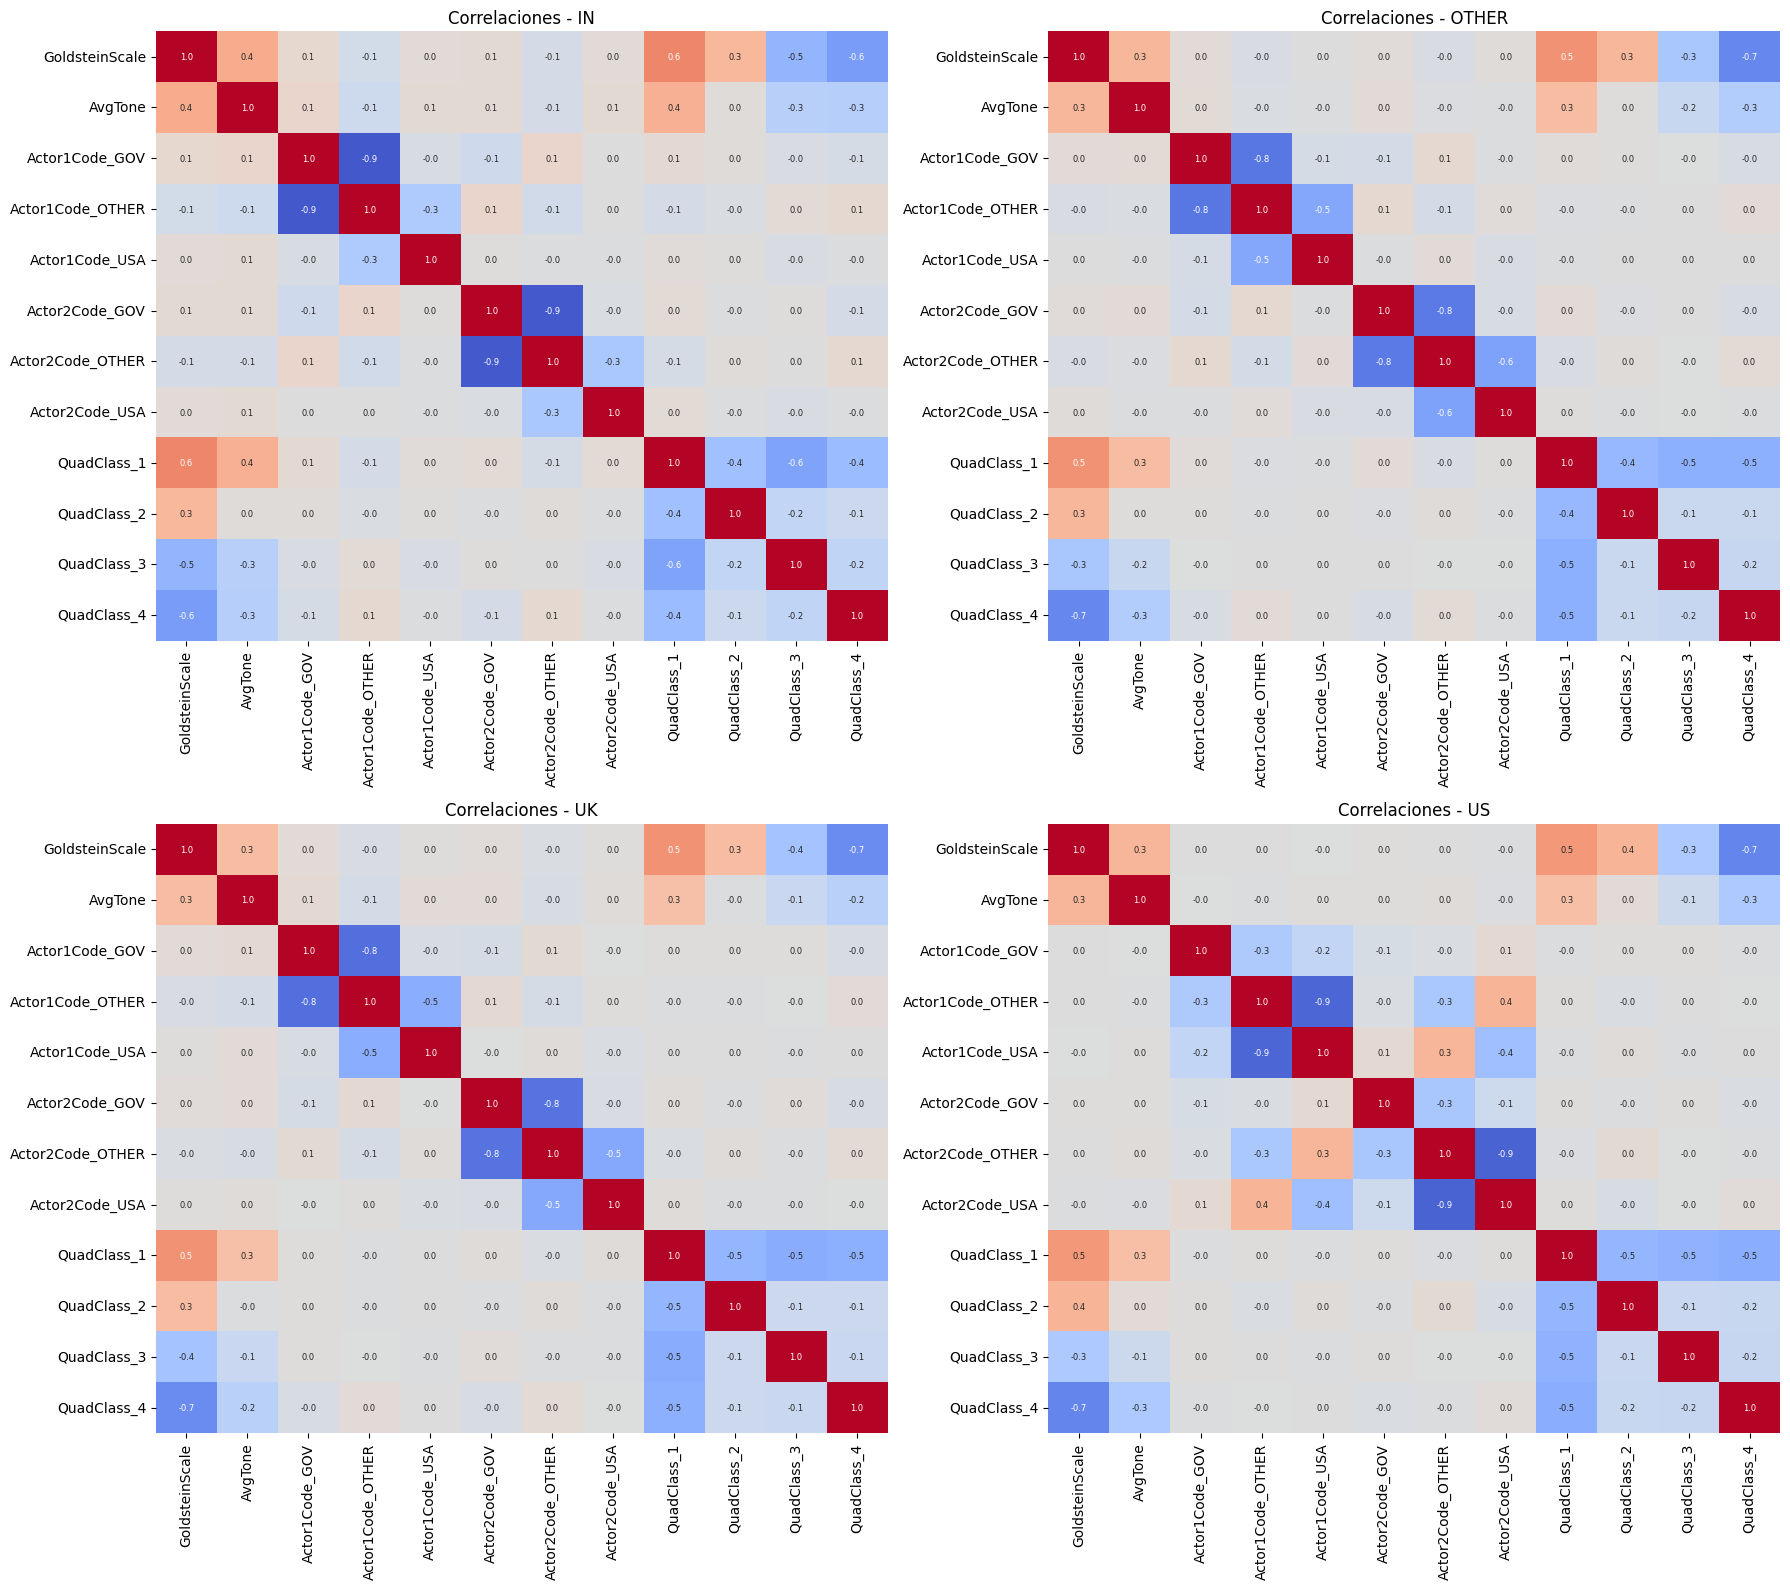

In [22]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Usamos X (sin dummies de país). La correlación no cambia con la estandarización.

# 1. Global
corr_global = X.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_global, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, annot_kws={"size": 7})
plt.title("Matriz de correlaciones - global")
plt.tight_layout()
plt.show()

# 2. Por país (una matriz por cada país que quedó tras la reducción)
paises = sorted(set(pais))
ncols = 2
nrows = int(np.ceil(len(paises) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(9 * ncols, 8 * nrows))
axes = np.array(axes).ravel()

for ax, p in zip(axes, paises):
    corr_p = X[pais == p].corr()
    sns.heatmap(corr_p, ax=ax, annot=True, fmt=".1f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, annot_kws={"size": 6}, cbar=False)
    ax.set_title(f"Correlaciones - {p}")

for ax in axes[len(paises):]:   # apagar ejes sobrantes
    ax.axis("off")

plt.tight_layout()
plt.show()

**3.1. Ajuste del modelo de PCA**

In [23]:
from sklearn.decomposition import PCA

# 1. Filtrar filas con NaN (una sola vez) y recortar el vector de países con la misma máscara
mask = df_matriz.notna().all(axis=1).to_numpy()
print(f"Filas eliminadas por NaN: {(~mask).sum()} de {len(mask)}")

df_pca = df_matriz[mask]
pais_pca = pais[mask]          # mismo largo y orden que df_pca (lo usás en el biplot)

# 2. Escalar la matriz completa (continuas + dummies)
X_scaled = StandardScaler().fit_transform(df_pca.astype("float32"))

# 3. Ajustar PCA con todos los componentes
pca = PCA()
scores = pca.fit_transform(X_scaled)       # coordenadas de cada evento en los PC
nombres_pc = [f"PC{i+1}" for i in range(pca.n_components_)]

# 4. Tabla de varianza explicada
var_tabla = pd.DataFrame({
    "autovalor": pca.explained_variance_,
    "var_explicada": pca.explained_variance_ratio_,
    "var_acumulada": pca.explained_variance_ratio_.cumsum(),
}, index=nombres_pc)
print(var_tabla.round(4))

# 5. Loadings: una fila por variable original, una columna por componente
loadings = pd.DataFrame(pca.components_.T, index=df_pca.columns, columns=nombres_pc)
print(loadings)

Filas eliminadas por NaN: 3 de 864002
      autovalor  var_explicada  var_acumulada
PC1      2.5367         0.1585         0.1585
PC2      2.4989         0.1562         0.3147
PC3      2.1168         0.1323         0.4470
PC4      1.3973         0.0873         0.5344
PC5      1.3458         0.0841         0.6185
PC6      1.2554         0.0785         0.6969
PC7      1.1768         0.0735         0.7705
PC8      1.1092         0.0693         0.8398
PC9      1.0502         0.0656         0.9054
PC10     0.7828         0.0489         0.9544
PC11     0.5845         0.0365         0.9909
PC12     0.1457         0.0091         1.0000
PC13     0.0000         0.0000         1.0000
PC14     0.0000         0.0000         1.0000
PC15     0.0000         0.0000         1.0000
PC16     0.0000         0.0000         1.0000
                                  PC1       PC2       PC3       PC4       PC5  \
GoldsteinScale               0.409015 -0.378417  0.020731  0.266676 -0.006361   
AvgTone           

**3.2/3. Análisis de la varianza explicada e interpretación de componentes**

En base al Scree plot retengo 8 componentes (~84% de la varianza). Como ninguna componente supera el 16% de la varianza, y la misma está muy repartida entre muchas componentes, se puede observar que los datos no son muy compresibles por PCA: se pasa de 12 dimensiones efectivas (los últimos 4 autovalores son nulos ya que son el dummy *k* de cada variable categórica) a 8.

Nombre propuesto para las componentes:

PC1: Cooperación en EEUU vs Conflicto en el resto de mundo;
PC2: Conflicto en EEUU vs Cooperación en el resto de mundo;
PC3: EEUU como agente vs EEUU como receptor;
PC4: Acción verbal vs Acción material;
PC5: Gobiernos de otros países vs Países principales;
PC6: Conflicto verbal gubernamental vs Acciones materiales;
PC7: EEUU y Gobierno, quién vs quién;
PC8: Conflicto verbal dirigido a EEUU vs Acciones materiales


**Nota**: Existen varias dificultades para interpretar las componentes, como la alta proporción de "OTHERS" (que internamente sería muy heterogenea) y la presencia de dummies.

PC1
GoldsteinScale                 0.409
ActionGeo_CountryCode_US       0.363
QuadClass_1                    0.362
QuadClass_4                   -0.342
ActionGeo_CountryCode_OTHER   -0.318
Actor1Code_OTHER              -0.286
Actor1Code_USA                 0.273
AvgTone                        0.250
Name: PC1, dtype: float32

PC2
ActionGeo_CountryCode_US       0.405
GoldsteinScale                -0.378
ActionGeo_CountryCode_OTHER   -0.370
QuadClass_1                   -0.349
QuadClass_4                    0.327
Actor1Code_USA                 0.304
Actor1Code_OTHER              -0.278
AvgTone                       -0.245
Name: PC2, dtype: float32

PC3
Actor2Code_OTHER            0.577
Actor2Code_USA             -0.478
Actor1Code_OTHER           -0.426
Actor1Code_USA              0.338
Actor2Code_GOV             -0.291
Actor1Code_GOV              0.222
QuadClass_2                 0.060
ActionGeo_CountryCode_US   -0.047
Name: PC3, dtype: float32

PC4
QuadClass_2                    0.757
Qu

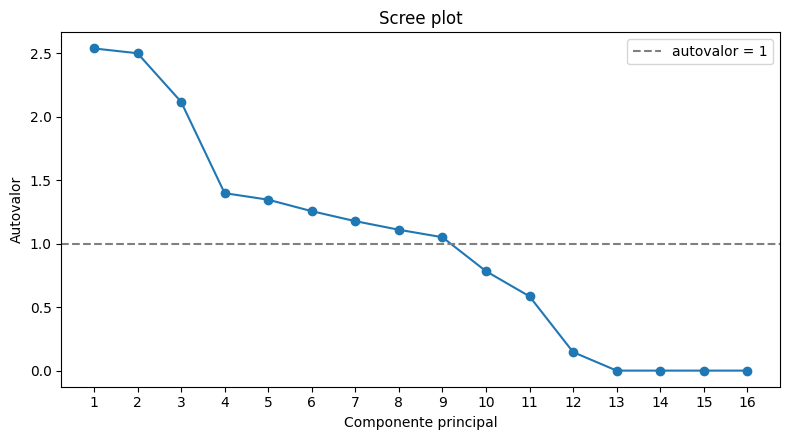

In [24]:
# Los 12 pesos más grandes de PC1 a PC8, ordenados por valor absoluto
for pc in ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"]:
    print(pc)
    print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8).round(3))
    print()


# Scree plot
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(nombres_pc) + 1), pca.explained_variance_, "o-")
plt.axhline(1, ls="--", color="gray", label="autovalor = 1")
plt.xlabel("Componente principal")
plt.ylabel("Autovalor")
plt.title("Scree plot")
plt.xticks(range(1, len(nombres_pc) + 1))
plt.legend()
plt.tight_layout()
plt.show()

**3.4. Visualización biplot y análisis de outliers**

En el biplot se pueden observar rayas que representan las combinaciones de categorías, con AvgTone, GoldsteinScale y QuadClass desplazando a los puntos dentro de cada línea diagonal. Resulta importante destacar que las componentes representadas en el gráfico explican solo el 31% de la varianza.

Los 0,1% de observaciones más extremas (distancia de Mahalanobis sobre 8 componentes) forman un grupo coherente: eventos en India con un gobierno como Actor2, de cooperación material o conflicto verbal y con tono más negativo que el resto. Son combinaciones infrecuentes de categorías individualmente frecuentes.

outliers: 863
                             outliers  resto  diferencia
AvgTone                        -3.641 -2.105      -1.537
Actor2Code_GOV                  0.981  0.051       0.930
Actor2Code_OTHER                0.000  0.859      -0.859
ActionGeo_CountryCode_IN        0.875  0.065       0.809
QuadClass_1                     0.009  0.611      -0.602
GoldsteinScale                 -0.073  0.420      -0.493
ActionGeo_CountryCode_OTHER     0.092  0.576      -0.484
QuadClass_2                     0.484  0.111       0.373


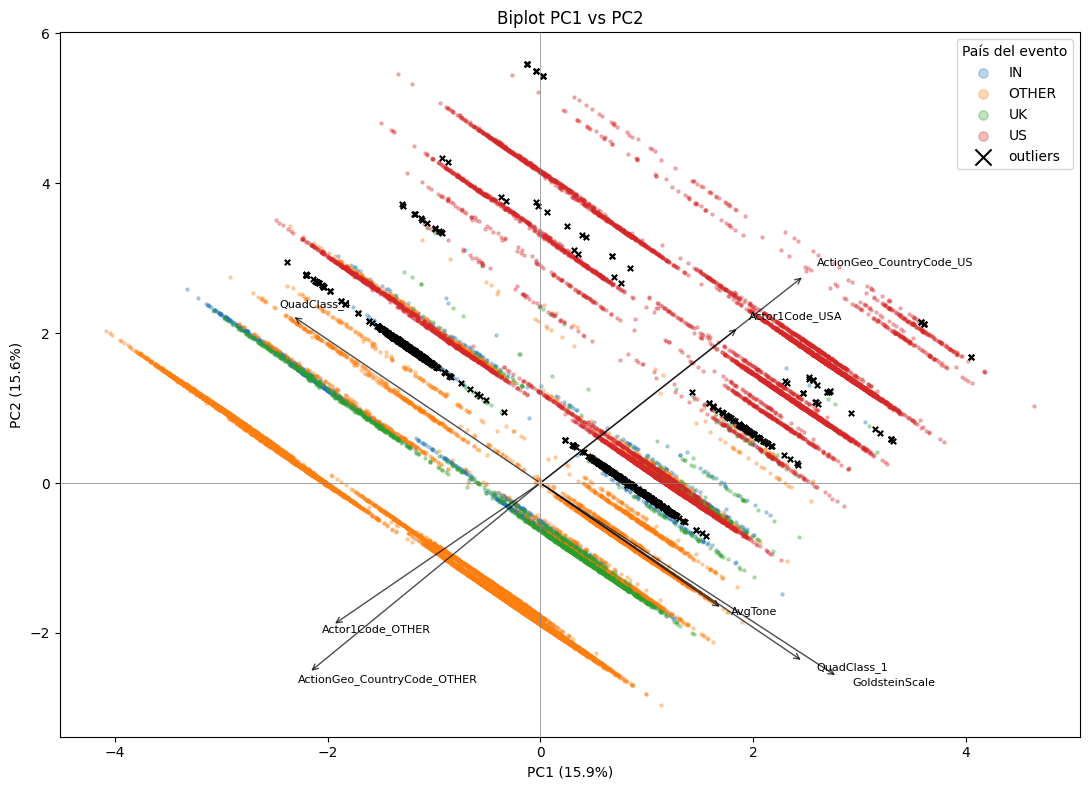

In [25]:
# 1. Outliers multivariantes (distancia de Mahalanobis sobre las k componentes retenidas)
k = 8
d2 = (scores[:, :k]**2 / pca.explained_variance_[:k]).sum(axis=1)
es_outlier = d2 > np.quantile(d2, 0.999)                      # 0,1% más extremo
print(f"outliers: {es_outlier.sum()}")

# ¿En qué se distinguen del resto?
comparacion = pd.DataFrame({
    "outliers": df_pca[es_outlier].mean(),
    "resto": df_pca[~es_outlier].mean(),
})
comparacion["diferencia"] = comparacion["outliers"] - comparacion["resto"]
print(comparacion.reindex(comparacion["diferencia"].abs().sort_values(ascending=False).index).head(8).round(3))

# 2. Muestra para graficar
rng = np.random.default_rng(42)
idx = rng.choice(len(scores), size=30000, replace=False)

fig, ax = plt.subplots(figsize=(11, 8))

# 3. Observaciones coloreadas por país y outliers
for p in np.unique(pais_pca):
    sel = idx[pais_pca[idx] == p]
    ax.scatter(scores[sel, 0], scores[sel, 1], s=5, alpha=0.3, label=p)
ax.scatter(scores[es_outlier, 0], scores[es_outlier, 1], s=15, color="black", marker="x", label="outliers")

# 4. Flechas de loadings
L = loadings[["PC1", "PC2"]]
escala = 0.5 * np.abs(scores[idx, :2]).max() / np.abs(L.values).max()
for var, (x, y) in L.iterrows():
    if np.hypot(x, y) > 0.3:
        ax.annotate("", xy=(x * escala, y * escala), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="black", alpha=0.7))
        ax.text(x * escala * 1.05, y * escala * 1.05, var, fontsize=8)

ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("Biplot PC1 vs PC2")
ax.legend(title="País del evento", markerscale=3)
plt.tight_layout()
plt.show()